<a href="https://colab.research.google.com/github/mbryan56/Intro-Machine-Learning-Projects/blob/main/Homework_6_Intro_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Loading Housing dataset from Drive: /content/drive/My Drive/Intro to ML/Datasets/Housing.csv


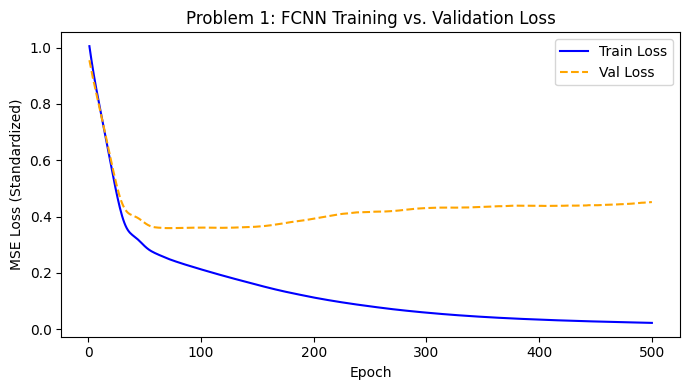


=================== PROBLEM 1 RESULTS SUMMARY ===================
Model                | MSE             | RMSE            | R2 Score  
--------------------------------------------------------------------
FCNN (PyTorch)       | 2006211493888.00 | 1416407.95      | 0.6031    
Linear Regression    | 1766312524832.81 | 1329026.91      | 0.6506    
SVR                  | 5598475003375.79 | 2366109.68      | -0.1076   


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and Preprocess Housing Dataset
file_path = '/content/drive/My Drive/Intro to ML/Datasets/Housing.csv'
if os.path.exists(file_path):
    print(f"Loading Housing dataset from Drive: {file_path}")
    housing_df = pd.read_csv(file_path)
else:
    raise FileNotFoundError(f"Could not find Housing.csv at {file_path}. Please check your Drive path.")

# Encode categorical features
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    if col in housing_df.columns and housing_df[col].dtype == object:
        housing_df[col] = housing_df[col].map({'yes': 1, 'no': 0})

if 'furnishingstatus' in housing_df.columns and housing_df['furnishingstatus'].dtype == object:
    housing_df['furnishingstatus'] = housing_df['furnishingstatus'].map({
        'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2
    })

# Define features (all columns except price) and target
X = housing_df.drop(columns=['price']).values
y = housing_df['price'].values

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Further split train into train/validation for FCNN loss tracking
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=42)

# Standardization
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_tr_s = scaler_X.fit_transform(X_tr)
X_val_s = scaler_X.transform(X_val)
X_test_s = scaler_X.transform(X_test)

y_tr_s = scaler_y.fit_transform(y_tr.reshape(-1, 1)).flatten()
y_val_s = scaler_y.transform(y_val.reshape(-1, 1)).flatten()
y_test_s = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# Convert to PyTorch tensors
X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr_s, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val_s, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)

# 2. FCNN Architecture (At least 2 hidden layers)
input_dim = X_tr_t.shape[1]
fcnn_model = nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

criterion = nn.MSELoss()
optimizer = optim.Adam(fcnn_model.parameters(), lr=0.001)

# Training Loop
epochs = 500
train_losses, val_losses = [], []

for epoch in range(1, epochs + 1):
    fcnn_model.train()
    optimizer.zero_grad()
    y_pred = fcnn_model(X_tr_t)
    loss = criterion(y_pred, y_tr_t)
    loss.backward()
    optimizer.step()

    # Validation loss
    fcnn_model.eval()
    with torch.no_grad():
        val_pred = fcnn_model(X_val_t)
        v_loss = criterion(val_pred, y_val_t)

    train_losses.append(loss.item())
    val_losses.append(v_loss.item())

# Plot Training and Validation Loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, epochs + 1), val_losses, label='Val Loss', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (Standardized)')
plt.title('Problem 1: FCNN Training vs. Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# Evaluate FCNN on Test Set (inverse transform predictions back to original scale)
fcnn_model.eval()
with torch.no_grad():
    y_pred_test_s = fcnn_model(X_test_t).numpy()
y_pred_fcnn = scaler_y.inverse_transform(y_pred_test_s).flatten()

fcnn_mse = mean_squared_error(y_test, y_pred_fcnn)
fcnn_rmse = np.sqrt(fcnn_mse)
fcnn_r2 = r2_score(y_test, y_pred_fcnn)

# 3. Traditional ML Baselines (Linear Regression & SVR)
# Fit on original training data with scaled features for fair comparison
lr_model = LinearRegression()
lr_model.fit(X_tr_s, y_tr)
y_pred_lr = lr_model.predict(X_test_s)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred_lr)

svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model.fit(X_tr_s, y_tr)
y_pred_svr = svr_model.predict(X_test_s)
svr_mse = mean_squared_error(y_test, y_pred_svr)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, y_pred_svr)

# Print Summary Results
print("\n=================== PROBLEM 1 RESULTS SUMMARY ===================")
print(f"{'Model':<20} | {'MSE':<15} | {'RMSE':<15} | {'R2 Score':<10}")
print("-" * 68)
print(f"{'FCNN (PyTorch)':<20} | {fcnn_mse:<15.2f} | {fcnn_rmse:<15.2f} | {fcnn_r2:<10.4f}")
print(f"{'Linear Regression':<20} | {lr_mse:<15.2f} | {lr_rmse:<15.2f} | {lr_r2:<10.4f}")
print(f"{'SVR':<20} | {svr_mse:<15.2f} | {svr_rmse:<15.2f} | {svr_r2:<10.4f}")
print("_" * 68)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading Breast Cancer dataset from Drive: /content/drive/My Drive/Intro to ML/Datasets/Cancer.csv
Identified target column: diagnosis
Original target unique values: ['M' 'B']
Dataset shape - Features: (569, 31), Targets: (569,)
Processed target distribution (0s and 1s): (array([0., 1.], dtype=float32), array([212, 357]))


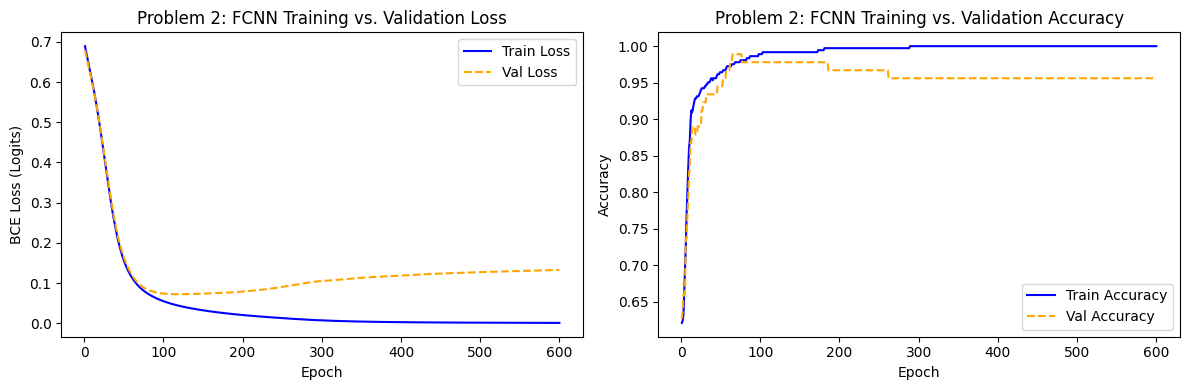


=================== PROBLEM 2 CLASSIFICATION SUMMARY ===================
Model                | Accuracy   | Precision  | Recall     | F1 Score  
--------------------------------------------------------------------
FCNN (PyTorch)       | 0.9561     | 0.9855     | 0.9444     | 0.9645    
Logistic Regression  | 0.9825     | 0.9861     | 0.9861     | 0.9861    
SVM (RBF)            | 0.9737     | 0.9726     | 0.9861     | 0.9793    


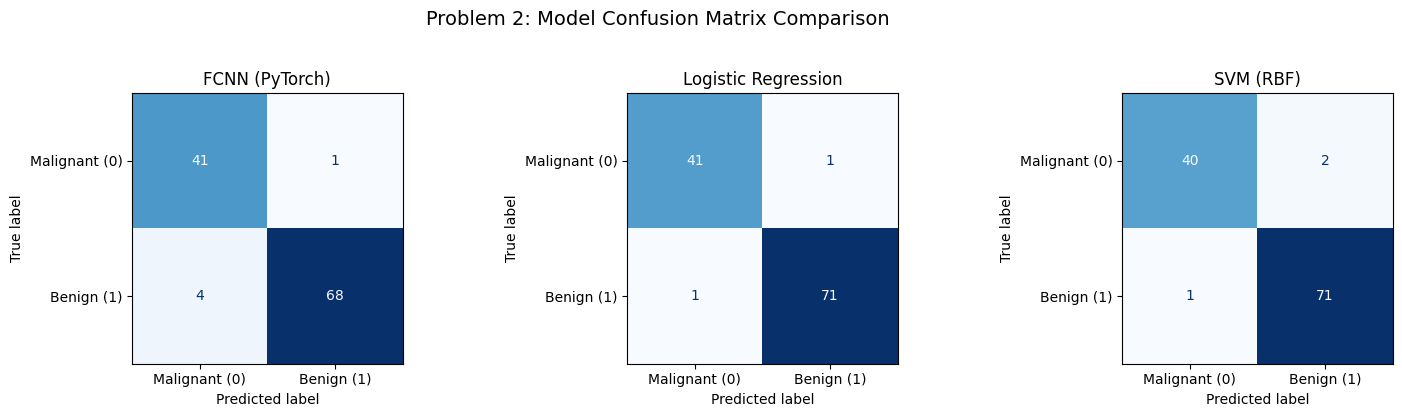

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

# 1. Load Breast Cancer Dataset from Google Drive
file_path_bc = '/content/drive/My Drive/Intro to ML/Datasets/Cancer.csv'

if os.path.exists(file_path_bc):
    print(f"Loading Breast Cancer dataset from Drive: {file_path_bc}")
    bc_df = pd.read_csv(file_path_bc)
else:
    raise FileNotFoundError(f"Could not find Cancer.csv at {file_path_bc}. Please check your Drive folder path.")

# Drop ID columns if present (e.g. 'id', 'Sample_ID', etc.)
for col in ['id', 'ID', 'Sample_ID']:
    if col in bc_df.columns:
        bc_df = bc_df.drop(columns=[col])

# Identify target column (commonly named 'target', 'diagnosis', or the last column)
target_col = 'target' if 'target' in bc_df.columns else ('diagnosis' if 'diagnosis' in bc_df.columns else bc_df.columns[-1])
print(f"Identified target column: {target_col}")

# Clean and map target labels to strictly 0 and 1
if bc_df[target_col].dtype == object or bc_df[target_col].nunique() <= 2:
    unique_vals = bc_df[target_col].unique()
    print(f"Original target unique values: {unique_vals}")
    if set(unique_vals).issubset({2, 4}):
        bc_df[target_col] = bc_df[target_col].map({2: 0, 4: 1})
    elif set(unique_vals).issubset({'M', 'B'}):
        bc_df[target_col] = bc_df[target_col].map({'M': 0, 'B': 1, 'malignant': 0, 'benign': 1})
    elif set(unique_vals).issubset({'malignant', 'benign'}):
        bc_df[target_col] = bc_df[target_col].map({'malignant': 0, 'benign': 1})
    else:
        # Fallback category conversion
        bc_df[target_col] = pd.factorize(bc_df[target_col])[0]

# Ensure all feature columns are numeric and handle any missing/NaN values
X_df = bc_df.drop(columns=[target_col])
for col in X_df.columns:
    X_df[col] = pd.to_numeric(X_df[col], errors='coerce')

# Fill any resulting NaNs with column means, and fallback to 0 if an entire column is NaN
X_df = X_df.fillna(X_df.mean()).fillna(0)

X_bc = X_df.values
y_bc = bc_df[target_col].values.astype(np.float32)

print(f"Dataset shape - Features: {X_bc.shape}, Targets: {y_bc.shape}")
print(f"Processed target distribution (0s and 1s): {np.unique(y_bc, return_counts=True)}")

# 2. 80/20 Train-Test Split with stratification
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bc, y_bc, test_size=0.20, random_state=42, stratify=y_bc
)

# Train/Val split for FCNN monitoring
X_tr_b, X_val_b, y_tr_b, y_val_b = train_test_split(
    X_train_b, y_train_b, test_size=0.20, random_state=42, stratify=y_train_b
)

# Standardization (fit on training data only)
scaler_bc = StandardScaler()
X_tr_b_s = scaler_bc.fit_transform(X_tr_b)
X_val_b_s = scaler_bc.transform(X_val_b)
X_test_b_s = scaler_bc.transform(X_test_b)

# Convert to PyTorch tensors
X_tr_bt = torch.tensor(X_tr_b_s, dtype=torch.float32)
y_tr_bt = torch.tensor(y_tr_b, dtype=torch.float32).unsqueeze(1)
X_val_bt = torch.tensor(X_val_b_s, dtype=torch.float32)
y_val_bt = torch.tensor(y_val_b, dtype=torch.float32).unsqueeze(1)
X_test_bt = torch.tensor(X_test_b_s, dtype=torch.float32)

# 3. FCNN Classifier Architecture (At least 2 hidden layers)
# Using BCEWithLogitsLoss (no final Sigmoid needed, highly stable training)
input_dim_bc = X_tr_bt.shape[1]
fcnn_clf = nn.Sequential(
    nn.Linear(input_dim_bc, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

criterion_clf = nn.BCEWithLogitsLoss()
optimizer_clf = optim.Adam(fcnn_clf.parameters(), lr=0.001)

epochs_bc = 600
train_losses_b, val_losses_b = [], []
train_accs_b, val_accs_b = [], []

for epoch in range(1, epochs_bc + 1):
    fcnn_clf.train()
    optimizer_clf.zero_grad()
    y_pred_logits = fcnn_clf(X_tr_bt)

    loss = criterion_clf(y_pred_logits.squeeze(), y_tr_bt.squeeze())

    loss.backward()
    optimizer_clf.step()

    # Calculate training accuracy using sigmoid on logits
    with torch.no_grad():
        train_probs = torch.sigmoid(y_pred_logits)
    train_preds = (train_probs >= 0.5).float()
    train_acc = (train_preds.squeeze() == y_tr_bt.squeeze()).float().mean().item()

    # Validation metrics
    fcnn_clf.eval()
    with torch.no_grad():
        val_logits = fcnn_clf(X_val_bt)
        val_loss = criterion_clf(val_logits.squeeze(), y_val_bt.squeeze())
        val_probs = torch.sigmoid(val_logits)
        val_preds = (val_probs >= 0.5).float()
        val_acc = (val_preds.squeeze() == y_val_bt.squeeze()).float().mean().item()

    train_losses_b.append(loss.item())
    val_losses_b.append(val_loss.item())
    train_accs_b.append(train_acc)
    val_accs_b.append(val_acc)

# Plot Loss and Accuracy Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_bc + 1), train_losses_b, label='Train Loss', color='blue')
plt.plot(range(1, epochs_bc + 1), val_losses_b, label='Val Loss', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('BCE Loss (Logits)')
plt.title('Problem 2: FCNN Training vs. Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_bc + 1), train_accs_b, label='Train Accuracy', color='blue')
plt.plot(range(1, epochs_bc + 1), val_accs_b, label='Val Accuracy', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Problem 2: FCNN Training vs. Validation Accuracy')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# Evaluate FCNN on Test Set
fcnn_clf.eval()
with torch.no_grad():
    test_logits = fcnn_clf(X_test_bt)
    test_probs = torch.sigmoid(test_logits)
    y_pred_fcnn_b = (test_probs >= 0.5).float().numpy().flatten()

fann_acc = accuracy_score(y_test_b, y_pred_fcnn_b)
fann_prec = precision_score(y_test_b, y_pred_fcnn_b, zero_division=0)
fann_rec = recall_score(y_test_b, y_pred_fcnn_b, zero_division=0)
fann_f1 = f1_score(y_test_b, y_pred_fcnn_b, zero_division=0)
fann_cm = confusion_matrix(y_test_b, y_pred_fcnn_b)

# 4. Traditional ML Baselines (Logistic Regression & SVM)
lr_clf = LogisticRegression(max_iter=1000)
lr_clf.fit(X_tr_b_s, y_tr_b)
y_pred_lr_b = lr_clf.predict(X_test_b_s)

lr_acc = accuracy_score(y_test_b, y_pred_lr_b)
lr_prec = precision_score(y_test_b, y_pred_lr_b, zero_division=0)
lr_rec = recall_score(y_test_b, y_pred_lr_b, zero_division=0)
lr_f1 = f1_score(y_test_b, y_pred_lr_b, zero_division=0)
lr_cm = confusion_matrix(y_test_b, y_pred_lr_b)

svm_clf = SVC(kernel='rbf', C=1.0)
svm_clf.fit(X_tr_b_s, y_tr_b)
y_pred_svm_b = svm_clf.predict(X_test_b_s)

svm_acc = accuracy_score(y_test_b, y_pred_svm_b)
svm_prec = precision_score(y_test_b, y_pred_svm_b, zero_division=0)
svm_rec = recall_score(y_test_b, y_pred_svm_b, zero_division=0)
svm_f1 = f1_score(y_test_b, y_pred_svm_b, zero_division=0)
svm_cm = confusion_matrix(y_test_b, y_pred_svm_b)

# Print Summary Results Table
print("\n=================== PROBLEM 2 CLASSIFICATION SUMMARY ===================")
print(f"{'Model':<20} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1 Score':<10}")
print("-" * 68)
print(f"{'FCNN (PyTorch)':<20} | {fann_acc:<10.4f} | {fann_prec:<10.4f} | {fann_rec:<10.4f} | {fann_f1:<10.4f}")
print(f"{'Logistic Regression':<20} | {lr_acc:<10.4f} | {lr_prec:<10.4f} | {lr_rec:<10.4f} | {lr_f1:<10.4f}")
print(f"{'SVM (RBF)':<20} | {svm_acc:<10.4f} | {svm_prec:<10.4f} | {svm_rec:<10.4f} | {svm_f1:<10.4f}")
print("=" * 68)

# Plot Confusion Matrices as Clean Heatmaps
models_eval = [
    ("FCNN (PyTorch)", y_pred_fcnn_b),
    ("Logistic Regression", y_pred_lr_b),
    ("SVM (RBF)", y_pred_svm_b)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, models_eval):
    cm = confusion_matrix(y_test_b, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant (0)', 'Benign (1)'])
    disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
    ax.set_title(f"{name}")
    disp.im_.colorbar.remove()

plt.suptitle("Problem 2: Model Confusion Matrix Comparison", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()
plt.close()